In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

%matplotlib inline

In [2]:
# Change this to the actual path of your Boston dataset CSV file.
# Example (Windows): r"C:\Users\YourName\Downloads\Boston.csv"
CSV_PATH = "Boston Predicted House Price - Boston Predicted House Price.csv"

df = pd.read_csv(CSV_PATH)

# Remove an unnecessary index column if the CSV contains one.
df = df.loc[:, ~df.columns.astype(str).str.match(r"^Unnamed")]

# Normalize column names to make target detection case-insensitive.
df.columns = df.columns.astype(str).str.strip()

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (506, 15)
Columns: ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'PRICE', 'Predicted Price(Approx.)']


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,PRICE,Predicted Price(Approx.)
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0,23.964398
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6,21.194154
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7,34.749864
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4,37.449864
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2,35.802312


In [3]:
# Boston Housing CSV files commonly name the house-price target MEDV or PRICE.
# If your target column has a different name, replace TARGET_COLUMN manually.
target_candidates = ["MEDV", "medv", "PRICE", "price", "TARGET", "target"]

TARGET_COLUMN = next(
    (col for col in target_candidates if col in df.columns),
    None
)

if TARGET_COLUMN is None:
    raise ValueError(
        "Could not identify the house-price target column. "
        f"Available columns: {df.columns.tolist()}. "
        "Set TARGET_COLUMN to the exact target column name in your CSV."
    )

# Convert all columns to numeric; invalid entries become NaN.
data = df.copy()
for col in data.columns:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Remove rows containing missing/non-numeric values.
data = data.dropna()

X = data.drop(columns=[TARGET_COLUMN])
y = data[TARGET_COLUMN]

if X.empty:
    raise ValueError("No feature columns remain after selecting the target.")

print("Target column:", TARGET_COLUMN)
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Target column: PRICE
Feature shape: (506, 14)
Target shape: (506,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.33,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (339, 14)
Testing features: (167, 14)


In [5]:
regressor = DecisionTreeRegressor(random_state=42)
regressor.fit(X_train, y_train)

y_pred = regressor.predict(X_test)

In [6]:
# r2_score expects actual values first and predicted values second.
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("Decision Tree Regression Results")
print("R2 Score:", r2)
print("Mean Squared Error:", mse)
print("Mean Absolute Error:", mae)

Decision Tree Regression Results
R2 Score: 0.9468417887950917
Mean Squared Error: 4.022934131736527
Mean Absolute Error: 1.1538922155688625


In [7]:
# 'auto' is not a valid max_features option for current versions
# of DecisionTreeRegressor. Use None, 'sqrt', or 'log2' instead.
parameter = {
    "criterion": ["squared_error", "friedman_mse", "absolute_error"],
    "splitter": ["best", "random"],
    "max_depth": [2, 3, 4, 5, 6, 8, 10, None],
    "max_features": [None, "sqrt", "log2"]
}

base_regressor = DecisionTreeRegressor(random_state=42)

regressorcv = GridSearchCV(
    estimator=base_regressor,
    param_grid=parameter,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

regressorcv.fit(X_train, y_train)

Fitting 5 folds for each of 144 candidates, totalling 720 fits


C:\Users\dhans\AppData\Roaming\Python\Python312\site-packages\sklearn\model_selection\_validation.py:493: FitFailedWarning: 
240 fits failed out of a total of 720.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
40 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\dhans\AppData\Roaming\Python\Python312\site-packages\sklearn\model_selection\_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\dhans\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py", line 1393, in wrapper
    estimator._validate_params()
  File "C:\Users\dhans\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py", line 554, in _validate_params
    valid

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['squared_error', 'friedman_mse', ...], 'max_depth': [2, 3, ...], 'max_features': [None, 'sqrt', ...], 'splitter': ['best', 'random']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple me

In [8]:
print("Best Parameters:")
print(regressorcv.best_params_)

best_regressor = regressorcv.best_estimator_
y_pred_tuned = best_regressor.predict(X_test)

print("\nTuned Decision Tree Regression Results")
print("R2 Score:", r2_score(y_test, y_pred_tuned))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred_tuned))
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred_tuned))

Best Parameters:
{'criterion': 'absolute_error', 'max_depth': 4, 'max_features': None, 'splitter': 'best'}

Tuned Decision Tree Regression Results
R2 Score: 0.9019087669242088
Mean Squared Error: 7.423398203592814
Mean Absolute Error: 1.1913173652694613


,Actual,Predicted
0,23.6,23.90
1,32.4,33.00
2,13.6,13.45
3,22.8,23.90
4,16.1,15.60
5,20.0,19.80
6,17.8,18.25
7,14.0,13.45
8,19.6,19.80
9,16.8,18.25


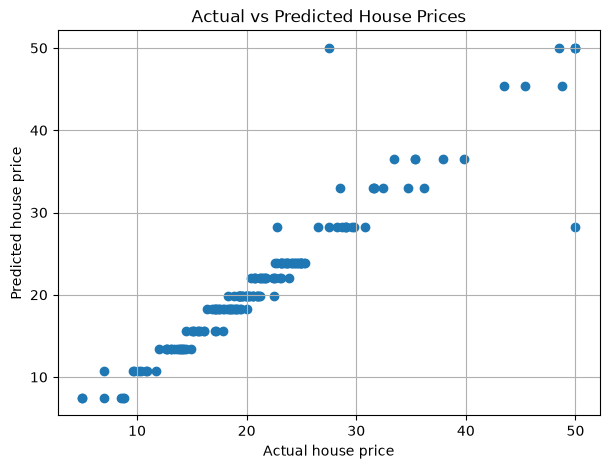

In [9]:
results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred_tuned
})

display(results.head(10))

plt.figure(figsize=(7, 5))
plt.scatter(results["Actual"], results["Predicted"])
plt.xlabel("Actual house price")
plt.ylabel("Predicted house price")
plt.title("Actual vs Predicted House Prices")
plt.grid(True)
plt.show()